In [1]:
# TODO: demonstrate difference between rate_adjustment true and false.

# How to: analyze_crit

In [2]:
from pandaict.reliability.monte_carlo import estimate_mttf_mttr
import networkx as nx
import matplotlib.pyplot as plt

init non-repairable net and plot

In [3]:
# initialize the graph object
G = nx.Graph()

# add the two nodes
G.add_node("Source")
G.add_node("Target")
G.add_node("A")         # unrelated node

# and connect them with an edge (link) which has a failure rate (to demonstrate failure behavior).
mttf_edge = 10.0  # h
mttr_edge = 0
G.add_edges_from([("Source", "A", {'mtbf_h': mttf_edge, 'mttr_h': mttr_edge})])
G.add_edges_from([("A", "Target", {'mtbf_h': mttf_edge, 'mttr_h': mttr_edge})])

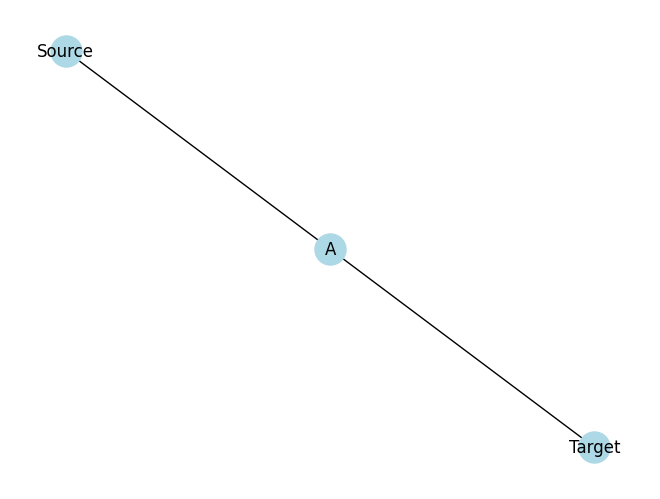

In [4]:
for u, v, data in G.edges(data=True):

    G[u][v]['weight'] = 1.0

nx.draw(G, with_labels=True, node_color='lightblue', node_size=500)
plt.show()

init repairable net

In [5]:
# initialize the graph object
G_rep = nx.Graph()

# add the two nodes
G_rep.add_node("Source")
G_rep.add_node("Target")
G_rep.add_node("A")         # unrelated node

# and connect them with an edge (link) which has a failure rate (to demonstrate failure behavior).
mttf_edge = 10.0    # h
mttr_edge = 1.0     # h
G_rep.add_edges_from([("Source", "A", {'mtbf_h': mttf_edge, 'mttr_h': mttr_edge})])
G_rep.add_edges_from([("A", "Target", {'mtbf_h': mttf_edge, 'mttr_h': mttr_edge})])

run calculations


CRITICAL COMPONENT ANALYSIS
Total events tracked: 1000

Score = Observed / Expected
  > 1.0: MORE critical
  ~ 1.0: As expected
  < 1.0: LESS critical
Norm: 2.0

──────────────────────────────────────────────────────────────────────
CRITICAL EDGES
──────────────────────────────────────────────────────────────────────
   1. ('Source', 'A'): Score=1.004, Count=502
   2. ('Target', 'A'): Score=0.996, Count=498

──────────────────────────────────────────────────────────────────────
CRITICAL NODES
──────────────────────────────────────────────────────────────────────
   1. A: Score=0.000, Count=0
   2. Target: Score=0.000, Count=0
   3. Source: Score=0.000, Count=0


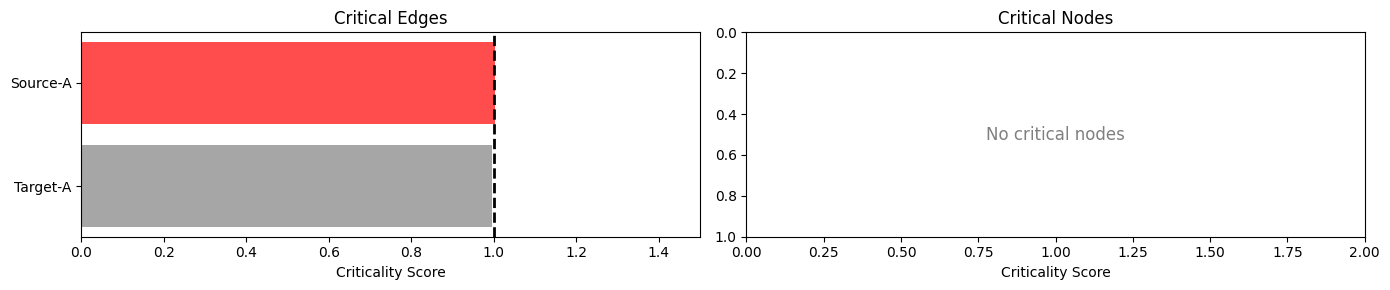

Running 200000 (1000 x 200) simulations in parallel...

CRITICAL COMPONENT ANALYSIS
Total events tracked: 217796

Score = Observed / Expected
  > 1.0: MORE critical
  ~ 1.0: As expected
  < 1.0: LESS critical
Norm: 2.0

──────────────────────────────────────────────────────────────────────
CRITICAL EDGES
──────────────────────────────────────────────────────────────────────
   1. ('Source', 'A'): Score=1.003, Count=109262
   2. ('Target', 'A'): Score=0.997, Count=108534

──────────────────────────────────────────────────────────────────────
CRITICAL NODES
──────────────────────────────────────────────────────────────────────
   1. A: Score=0.000, Count=0
   2. Target: Score=0.000, Count=0
   3. Source: Score=0.000, Count=0


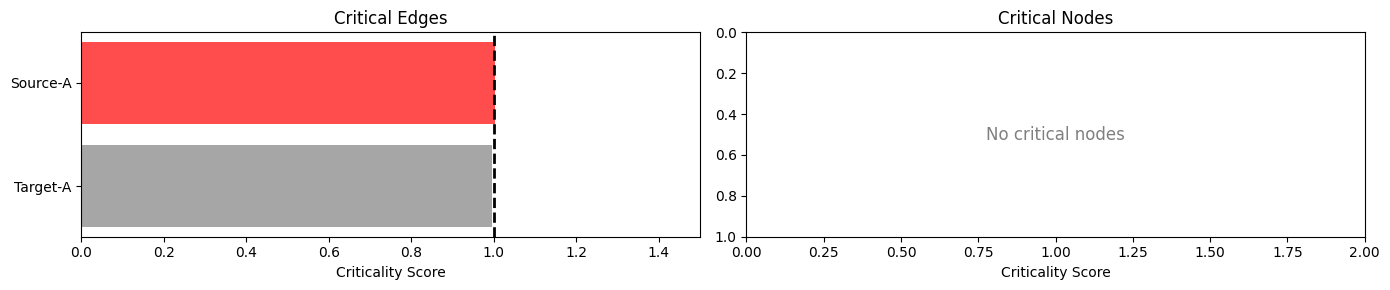

In [6]:
res_dict = estimate_mttf_mttr(G, sources='Source', targets='Target', analyze_crit=True, parallel=False)
res_dict_repairable = estimate_mttf_mttr(G_rep, sources='Source', targets='Target', analyze_crit=True)



In [7]:
mttf = res_dict['mttf']
#mttf_rep = res_dict_repairable['mttf']

print(mttf)
#print(mttf_rep)

4.889762603313345
